### The experts' proficiency explanations ("why") as the text side of the CCA

Every expert who commented on a take also rated it 1-10 and wrote why (`expert_commentary/<take>/<expert>/data.json`,
`proficiency.why` / `proficiency.rating`). Unlike the good/tip moments, this covers every take (Rock Climbing too),
is a judgment of the whole take (the same granularity as the proficiency label, no timestamps), and is about how
well the person did. Pairs are (take video, one expert's text); at test time only video is used.

1. **Text ceiling**: how well the experts' text (and their ratings alone) predicts the level of held-out takes.
2. **CCA** between take video and the text "Rating r/10: why" (and the why alone), scenario-centered, PCA-64 per
   side, 16 components, folds split by participant.
3. **Proficiency probes** on test take video: full, the why-CCA subspace (with and without the rating in the text),
   its residual, and controls of the same size: top-16 PCA, random 16-d subspaces, and **label PLS**, a subspace
   chosen from the train labels alone (PLS of video on the level one-hot and mean rating). If the why subspace only
   matches label PLS, the text adds nothing beyond the numbers.

Video features (all cached by earlier notebooks): zero-shot Qwen3.5-4B, the mean of each take's back-to-back
20-frame 1 FPS windows at layers 8 / 16 / 32 (`good_tip_cca.ipynb`); SkillFormer-Ego, the mean of each take's
back-to-back 64-frame windows, layer 6 and last layer (`skillformer_goodtip.ipynb`).

In [1]:
import ast
import json
from collections import Counter, defaultdict
from pathlib import Path

import av
import numpy as np

# Same takes as the earlier idea_1 notebooks: video and transcribed expert commentary, train / SkillFormer test split.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"
WINDOW_FPS = 1

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m):
    parts = m["video_paths"]["ego"].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def has_commentary(take):
    """Whether any expert recorded transcribed commentary on the take (the take set of the earlier notebooks)."""
    for data_path in (COMMENTARY_ROOT / take).rglob("data.json"):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        if any(transcripts.get(a.get("recording_path"), {}).get("text", "").strip() for a in data.get("annotations", [])):
            return True
    return False

def num_seconds(path):
    """Number of 1 FPS frames decode_1fps() gets from the video (frames 0, 30, 60, ... at 30 FPS)."""
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        step = round(float(stream.average_rate) / WINDOW_FPS)
        return (stream.frames - 1) // step + 1

with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not video_path(m).exists() or not has_commentary(take_name(m)):
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"], "score": LEVELS[m["proficiency_score"]],
                      "participant": m["origin_participant_id"], "video": str(video_path(m)),
                      "seconds": num_seconds(video_path(m))})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
clip_of = {clip["take_name"]: clip for split_list in clips_by_split.values() for clip in split_list}
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} takes, {sum(c['seconds'] for c in split_list) / 3600:.1f} h of video")

# Good executions (polarity 1) and tips for improvement (polarity 0) of those takes. Each entry's "list" is a Python
# list literal of sentences (NaN for a few blank entries, which are dropped).
POLARITIES = {"good_executions": (1, "Good execution"), "tips_for_improvement": (0, "Tip for improvement")}

def entry_sentences(entry):
    if not isinstance(entry.get("list"), str):
        return []
    try:
        items = ast.literal_eval(entry["list"])
    except (ValueError, SyntaxError):
        items = [entry["list"]]
    return [s.strip() for s in (items if isinstance(items, list) else [items]) if isinstance(s, str) and s.strip()]

demonstration = {}
for annotation_file in ("proficiency_demonstration_train.json", "proficiency_demonstration_val.json"):
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        demonstration.update({take_name(m): m for m in json.load(file)["annotations"]})

moments = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        m = demonstration.get(clip["take_name"])
        for key, (polarity, tag) in POLARITIES.items():
            for entry in (m or {}).get(key, []):
                sentences = entry_sentences(entry)
                if sentences:
                    moments.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                                    "polarity": polarity, "time": float(entry["video_time"]), "expert": entry["expert_uid"],
                                    "text": f"{tag}: {' '.join(sentences)}"})
covered = {m["take_name"] for m in moments}
for split in ("train", "test"):
    split_moments = [m for m in moments if m["split"] == split]
    print(f"{split}: {sum(c['take_name'] in covered for c in clips_by_split[split])} takes with moments, "
          f"{sum(m['polarity'] for m in split_moments)} good executions, {sum(1 - m['polarity'] for m in split_moments)} tips; "
          f"scenarios {dict(Counter(m['scenario'] for m in split_moments))}")

train: 1174 takes, 36.3 h of video
test: 164 takes, 4.9 h of video
train: 371 takes with moments, 8241 good executions, 8326 tips; scenarios {'Cooking': 5033, 'Basketball': 7358, 'Dance': 1841, 'Music': 2228, 'Soccer': 107}
test: 61 takes with moments, 1315 good executions, 1161 tips; scenarios {'Basketball': 1315, 'Cooking': 481, 'Music': 264, 'Dance': 416}


In [2]:
# Every expert's rating and why for each take.
def take_whys(take):
    whys = []
    for path in sorted((COMMENTARY_ROOT / take).glob("*/data.json")):
        proficiency = json.loads(path.read_text(encoding="utf-8")).get("proficiency") or {}
        why = (proficiency.get("why") or "").strip()
        if not why:
            continue
        try:
            rating = float(proficiency.get("rating"))
        except (TypeError, ValueError):
            rating = None
        whys.append({"expert": path.parent.name, "why": why, "rating": rating})
    return whys

pairs = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        for w in take_whys(clip["take_name"]):
            rated = f"Rating {w['rating']:g}/10: {w['why']}" if w["rating"] is not None else w["why"]
            pairs.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                          "participant": clip["participant"], "score": clip["score"], "rating": w["rating"],
                          "rated": rated, "plain": w["why"]})
for split in ("train", "test"):
    split_pairs = [p for p in pairs if p["split"] == split]
    print(f"{split}: {len(split_pairs)} whys over {len({p['take_name'] for p in split_pairs})} of "
          f"{len(clips_by_split[split])} takes; {sum(p['rating'] is None for p in split_pairs)} without a rating")

train: 4344 whys over 1174 of 1174 takes; 83 without a rating
test: 660 whys over 164 of 164 takes; 11 without a rating


In [3]:
import torch
from tqdm.auto import tqdm
from transformers import AutoModelForMultimodalLM, AutoProcessor, BitsAndBytesConfig

# Zero-shot Qwen3.5-4B text embeddings, pooled exactly as in good_tip_cca.ipynb (mean over the text's own tokens).
model_id = "Qwen/Qwen3.5-4B"
bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.bfloat16,
                                bnb_4bit_use_double_quant=True)
model = AutoModelForMultimodalLM.from_pretrained(model_id, quantization_config=bnb_config, device_map="auto").eval()
processor = AutoProcessor.from_pretrained(model_id)
LAYERS = {"early": 8, "middle": 16, "last": 32}
EMBEDDING_DIR = Path("embeddings")
DECODER_LAYERS = [m for m in model.modules() if type(m).__name__ == "Qwen3_5DecoderLayer"]
_pool_mask, _pooled = None, {}

def _make_pool_hook(layer):
    def hook(module, args, output):
        if _pool_mask is None:
            return
        hidden = output[0] if isinstance(output, tuple) else output
        mask = _pool_mask.unsqueeze(-1).float()
        _pooled[layer] = ((hidden.float() * mask).sum(1) / mask.sum(1)).cpu()
    return hook

for layer in LAYERS.values():
    DECODER_LAYERS[layer - 1].register_forward_hook(_make_pool_hook(layer))

@torch.inference_mode()
def text_embedding(text):
    """(len(LAYERS), hidden): the text alone in a user turn, pooled over its own tokens (not the chat markup)."""
    global _pool_mask
    prompt = processor.apply_chat_template([{"role": "user", "content": [{"type": "text", "text": text}]}], tokenize=False)
    start = prompt.index(text)
    batch = processor.tokenizer(prompt, return_tensors="pt", return_offsets_mapping=True)
    offsets = batch.pop("offset_mapping")[0]
    _pool_mask = ((offsets[:, 0] >= start) & (offsets[:, 1] <= start + len(text)) & (offsets[:, 1] > offsets[:, 0]))[None].to(model.device)
    _pooled.clear()
    try:
        with torch.autocast("cuda", dtype=torch.bfloat16):
            model(**batch.to(model.device), logits_to_keep=1)
    finally:
        _pool_mask = None
    return torch.stack([_pooled[layer][0] for layer in LAYERS.values()])

TEXT_CACHE = EMBEDDING_DIR / "qwen35_base_why_text.pt"
text_cache = torch.load(TEXT_CACHE) if TEXT_CACHE.exists() else {}
texts = sorted({p[k] for p in pairs for k in ("rated", "plain")} - set(text_cache))
print(f"{len(texts)} texts to embed")
for k, text in enumerate(tqdm(texts), 1):
    text_cache[text] = text_embedding(text)
    if k % 1000 == 0:
        torch.save(text_cache, TEXT_CACHE)
torch.save(text_cache, TEXT_CACHE)
del model
torch.cuda.empty_cache()

W1115 13:13:33.306000 3120 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

9037 texts to embed


  0%|          | 0/9037 [00:00<?, ?it/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


In [4]:
# Take-level video features from the caches of the earlier notebooks: {representation: {take: vector}}.
def qwen_tile_windows(take, length=20):
    seconds = clip_of[take]["seconds"]
    windows = []
    for start in range(0, seconds, length):
        size = min(length, seconds - start)
        size -= size % 2
        if size >= 2 and (size >= length // 2 or not windows):
            windows.append((start, size))
    return windows

def skillformer_tile_starts(n, T=64):
    if n <= T:
        return [0]
    starts = list(range(0, n - T + 1, T))
    if n - (starts[-1] + T) >= T // 2:
        starts.append(n - T)
    return starts

VIDEO = {}
qwen_cache = torch.load(EMBEDDING_DIR / "qwen35_base_goodtip_windows.pt")
for layer_index, (name, layer) in enumerate(LAYERS.items()):
    VIDEO[f"Qwen layer {layer}"] = {take: torch.stack([qwen_cache[take][w][layer_index] for w in qwen_tile_windows(take)])
                                    .double().mean(0).numpy() for take in clip_of}
del qwen_cache

skillformer_cache = torch.load(EMBEDDING_DIR / "skillformer_ego_goodtip_windows.pt")
SKILLFORMER_SLICES = {"SkillFormer layer 6": slice(0, 768), "SkillFormer last layer": slice(768, 1536)}
skillformer_logits = {}
for take, clip in clip_of.items():
    with av.open(clip["video"]) as container:
        n = (container.streams.video[0].frames - 1) // 4 + 1
    tiles = torch.stack([skillformer_cache[take][s] for s in skillformer_tile_starts(n)]).double().mean(0).numpy()
    for rep, columns in SKILLFORMER_SLICES.items():
        VIDEO.setdefault(rep, {})[take] = tiles[columns]
    skillformer_logits[take] = tiles[2304:2308]
del skillformer_cache
print({rep: next(iter(v.values())).shape for rep, v in VIDEO.items()})

{'Qwen layer 8': (2560,), 'Qwen layer 16': (2560,), 'Qwen layer 32': (2560,), 'SkillFormer layer 6': (768,), 'SkillFormer last layer': (768,)}


#### 1. How much do the experts' text and ratings say about the level?

Take features: the mean over the take's experts. Probes (logistic regression on the scenario one-hot + features,
regularization by 5-fold CV) trained on the train takes, scored on the test takes; also 5-fold CV on the train takes
split by participant, which picks the text layer used in the CCA.

In [5]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

train_clips, test_clips = clips_by_split["train"], clips_by_split["test"]
train_scores = np.array([c["score"] for c in train_clips])
test_scores = np.array([c["score"] for c in test_clips])
train_scenarios = np.array([c["scenario"] for c in train_clips])
train_participants = np.array([c["participant"] for c in train_clips])
scenario_encoder = OneHotEncoder(handle_unknown="ignore").fit(train_scenarios[:, None])
onehot = {split: scenario_encoder.transform([[c["scenario"]] for c in clips_by_split[split]]).toarray() for split in ("train", "test")}

def make_probe():
    return make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=5, max_iter=5000, n_jobs=-1))

def probe(train_x, test_x):
    model = make_probe().fit(np.hstack([onehot["train"], train_x]), train_scores)
    return model.predict(np.hstack([onehot["test"], test_x]))

def cv_accuracy(train_x):
    """5-fold CV accuracy on the train takes, folds split by participant."""
    X = np.hstack([onehot["train"], train_x])
    hits = np.zeros(len(X))
    for fit, held_out in GroupKFold(5).split(X, train_scores, train_participants):
        hits[held_out] = make_probe().fit(X[fit], train_scores[fit]).predict(X[held_out]) == train_scores[held_out]
    return hits.mean()

def scenario_centered(features):
    """{split: (takes, dims)} minus the train takes' mean for each take's scenario."""
    means = {s: features["train"][train_scenarios == s].mean(0) for s in np.unique(train_scenarios)}
    fallback = np.mean(list(means.values()), 0)
    return {split: x - np.stack([means.get(c["scenario"], fallback) for c in clips_by_split[split]])
            for split, x in features.items()}

pairs_of = defaultdict(list)
for p in pairs:
    pairs_of[p["take_name"]].append(p)

def take_text(key, layer_index):
    return scenario_centered({split: np.stack([np.mean([text_cache[p[key]][layer_index].double().numpy() for p in pairs_of[c["take_name"]]], 0)
                                               for c in clips_by_split[split]]) for split in ("train", "test")})

def take_rating():
    def mean_rating(take):
        ratings = [p["rating"] for p in pairs_of[take] if p["rating"] is not None]
        return np.mean(ratings) if ratings else np.nan
    raw = {split: np.array([[mean_rating(c["take_name"])] for c in clips_by_split[split]]) for split in ("train", "test")}
    fill = np.nanmean(raw["train"])
    return {split: np.nan_to_num(x, nan=fill) for split, x in raw.items()}

text_predictions = {"scenario only": probe(np.zeros((len(train_clips), 0)), np.zeros((len(test_clips), 0)))}
ratings = take_rating()
text_predictions["mean rating"] = probe(ratings["train"], ratings["test"])
text_cv = {"scenario only": cv_accuracy(np.zeros((len(train_clips), 0))), "mean rating": cv_accuracy(ratings["train"])}
for key, label in (("rated", "rating + why"), ("plain", "why only")):
    for layer_index, (name, layer) in enumerate(LAYERS.items()):
        features = take_text(key, layer_index)
        text_predictions[f"{label}, layer {layer}"] = probe(features["train"], features["test"])
        text_cv[f"{label}, layer {layer}"] = cv_accuracy(features["train"])

print("Level from the experts' text (no video): train CV accuracy (folds by participant), test accuracy, test balanced accuracy")
for key, prediction in text_predictions.items():
    print(f"  {key:<24} CV {text_cv[key]:.3f}   test {accuracy_score(test_scores, prediction):.3f}   "
          f"balanced {balanced_accuracy_score(test_scores, prediction):.3f}")
TEXT_LAYER_INDEX = max(range(len(LAYERS)), key=lambda i: text_cv[f"rating + why, layer {list(LAYERS.values())[i]}"])
print(f"\nText layer for the CCA (best train CV, rating + why): layer {list(LAYERS.values())[TEXT_LAYER_INDEX]}")

Level from the experts' text (no video): train CV accuracy (folds by participant), test accuracy, test balanced accuracy
  scenario only            CV 0.330   test 0.433   balanced 0.445
  mean rating              CV 0.400   test 0.476   balanced 0.459
  rating + why, layer 8    CV 0.359   test 0.427   balanced 0.395
  rating + why, layer 16   CV 0.365   test 0.463   balanced 0.389
  rating + why, layer 32   CV 0.363   test 0.457   balanced 0.398
  why only, layer 8        CV 0.343   test 0.372   balanced 0.328
  why only, layer 16       CV 0.359   test 0.433   balanced 0.379
  why only, layer 32       CV 0.364   test 0.409   balanced 0.377

Text layer for the CCA (best train CV, rating + why): layer 16


#### 2. CCA: take video vs. each expert's text

One pair per (take, expert why); the take's video vector repeats across its experts. Both sides scenario-centered
(train means), video PCA fit on the unique train takes, text PCA on the train pairs, 64 dims each, 16 components.
Held-out: 5 folds split by participant; each component's canonical correlation on held-out pairs (with a
shuffled-pair 95th percentile), and the Spearman correlation of its video variate with the level over the held-out
takes (oriented on the training folds).

In [6]:
from scipy.stats import spearmanr
from sklearn.cross_decomposition import CCA, PLSRegression

PCA_DIMS, N_COMPONENTS, N_PERMUTATIONS = 64, 16, 100
TEXT_KEYS = {"rated": "rating + why", "plain": "why only"}
train_pairs = [p for p in pairs if p["split"] == "train"]
test_pairs = [p for p in pairs if p["split"] == "test"]
take_index = {split: {c["take_name"]: i for i, c in enumerate(clips_by_split[split])} for split in ("train", "test")}
pair_take = {split: np.array([take_index[split][p["take_name"]] for p in pairs if p["split"] == split]) for split in ("train", "test")}
pair_participant = np.array([p["participant"] for p in train_pairs])
pair_scenario = {split: np.array([p["scenario"] for p in pairs if p["split"] == split]) for split in ("train", "test")}

def pair_text(key):
    """{split: (pairs, hidden)} text embeddings at the chosen layer, minus the train pairs' scenario means."""
    raw = {split: np.stack([text_cache[p[key]][TEXT_LAYER_INDEX].double().numpy() for p in pairs if p["split"] == split])
           for split in ("train", "test")}
    means = {s: raw["train"][pair_scenario["train"] == s].mean(0) for s in np.unique(pair_scenario["train"])}
    fallback = np.mean(list(means.values()), 0)
    return {split: x - np.stack([means.get(s, fallback) for s in pair_scenario[split]]) for split, x in raw.items()}

def canonical_correlations(a, b):
    a, b = a - a.mean(0), b - b.mean(0)
    return (a * b).sum(0) / np.sqrt((a ** 2).sum(0) * (b ** 2).sum(0))

def fit_cca(video_takes, take_rows, text_pairs, pair_rows):
    """video_takes: (takes, d) scenario-centered; take_rows: takes used; text_pairs / pair_rows: pairs used.
    PCA of video on the unique takes, of text on the pairs; CCA on the pairs."""
    pca_video = PCA(PCA_DIMS, svd_solver="full").fit(video_takes[np.unique(take_rows)])
    pca_text = PCA(PCA_DIMS, svd_solver="full").fit(text_pairs[pair_rows])
    v = pca_video.transform(video_takes[pair_take["train"][pair_rows]])
    cca = CCA(n_components=N_COMPONENTS, max_iter=2000).fit(v, pca_text.transform(text_pairs[pair_rows]))
    directions = pca_video.components_.T @ (cca.x_rotations_ / cca._x_std[:, None])
    return {"pca_video": pca_video, "pca_text": pca_text, "cca": cca, "mean": pca_video.mean_,
            "basis": np.linalg.qr(directions)[0]}

def transform_pairs(result, video_takes, take_of_pair, text):
    return result["cca"].transform(result["pca_video"].transform(video_takes[take_of_pair]), result["pca_text"].transform(text))

def video_variates(result, video_takes):
    v = result["pca_video"].transform(video_takes)
    return (v - result["cca"]._x_mean) / result["cca"]._x_std @ result["cca"].x_rotations_

rng = np.random.default_rng(0)
video_features = {rep: scenario_centered({split: np.stack([VIDEO[rep][c["take_name"]] for c in clips_by_split[split]])
                                          for split in ("train", "test")}) for rep in VIDEO}
texts_by_key = {key: pair_text(key) for key in TEXT_KEYS}
cca_results, cca_cv, cca_test = {}, {}, {}
for rep in tqdm(VIDEO):
    video = video_features[rep]
    for key in TEXT_KEYS:
        text = texts_by_key[key]
        folds = {"r": [], "null": [], "rho": []}
        for fit, held_out in GroupKFold(5).split(np.arange(len(train_pairs)), groups=pair_participant):
            result = fit_cca(video["train"], pair_take["train"][fit], text["train"], fit)
            v_shared, t_shared = transform_pairs(result, video["train"], pair_take["train"][held_out], text["train"][held_out])
            folds["r"].append(canonical_correlations(v_shared, t_shared))
            folds["null"].append(np.quantile([canonical_correlations(v_shared, t_shared[rng.permutation(len(t_shared))])
                                              for _ in range(N_PERMUTATIONS)], 0.95, axis=0))
            fit_takes, held_takes = np.unique(pair_take["train"][fit]), np.unique(pair_take["train"][held_out])
            sign = np.sign([spearmanr(column, train_scores[fit_takes]).statistic
                            for column in video_variates(result, video["train"][fit_takes]).T])
            held = video_variates(result, video["train"][held_takes]) * sign
            folds["rho"].append([spearmanr(column, train_scores[held_takes]).statistic for column in held.T])
        cca_cv[rep, key] = {k: np.mean(v, 0) for k, v in folds.items()}
        result = cca_results[rep, key] = fit_cca(video["train"], pair_take["train"], text["train"], np.arange(len(train_pairs)))
        v_shared, t_shared = transform_pairs(result, video["test"], pair_take["test"], text["test"])
        sign = np.sign([spearmanr(column, train_scores).statistic for column in video_variates(result, video["train"]).T])
        cca_test[rep, key] = {"r": canonical_correlations(v_shared, t_shared),
                              "rho": np.array([spearmanr(column, test_scores).statistic
                                               for column in (video_variates(result, video["test"]) * sign).T])}

print(f"CCA: {len(train_pairs)} train pairs ({len(train_clips)} takes), {len(test_pairs)} test pairs; text layer "
      f"{list(LAYERS.values())[TEXT_LAYER_INDEX]}; held-out = 5 folds by participant\n")
for (rep, key), cv in cca_cv.items():
    test = cca_test[rep, key]
    print(f"{rep}, {TEXT_KEYS[key]}: {int((cv['r'] > cv['null']).sum())}/{N_COMPONENTS} components above the shuffled "
          f"95th percentile")
    print("  component              " + "".join(f"{k:>6}" for k in range(1, 9)))
    print("  held-out r             " + "".join(f"{r:>6.2f}" for r in cv["r"][:8]))
    print("  test r                 " + "".join(f"{r:>6.2f}" for r in test["r"][:8]))
    print("  held-out rho w/ level  " + "".join(f"{r:>6.2f}" for r in cv["rho"][:8]))
    print("  test rho w/ level      " + "".join(f"{r:>6.2f}" for r in test["rho"][:8]))

  0%|          | 0/5 [00:00<?, ?it/s]

CCA: 4344 train pairs (1174 takes), 660 test pairs; text layer 16; held-out = 5 folds by participant

Qwen layer 8, rating + why: 16/16 components above the shuffled 95th percentile
  component                   1     2     3     4     5     6     7     8
  held-out r               0.51  0.31  0.29  0.23  0.31  0.28  0.23  0.10
  test r                   0.53  0.49  0.39  0.36  0.26  0.42  0.25  0.23
  held-out rho w/ level    0.07  0.20 -0.00  0.13  0.04  0.01  0.06 -0.00
  test rho w/ level       -0.03  0.29 -0.08 -0.08  0.04  0.08  0.08  0.15
Qwen layer 8, why only: 16/16 components above the shuffled 95th percentile
  component                   1     2     3     4     5     6     7     8
  held-out r               0.48  0.22  0.25  0.25  0.29  0.18  0.16  0.11
  test r                   0.50  0.43  0.40  0.41  0.17  0.23  0.26  0.32
  held-out rho w/ level    0.12  0.13  0.18  0.06  0.07  0.04  0.11 -0.07
  test rho w/ level        0.04  0.30  0.02  0.00  0.02  0.05 -0.14  0.02
Qw

#### 3. Proficiency probes on test video

Per video representation, the scenario-centered take vector projected onto: nothing (**full**), the why-CCA's 16
video directions (**why-CCA**, text with and without the rating), the rest (**residual**), and same-size controls:
**top-16 PCA**, **random** 16-d subspaces of the PCA-64 space (10 draws), and **label PLS** (16 PLS directions of
video against the train takes' level one-hot and mean rating, so chosen by the labels with no text). Every probe
also gets the scenario one-hot.

In [7]:
N_RANDOM = 10

def project(x, mean, basis):
    return (x - mean) @ basis @ basis.T

def label_pls_basis(video_train):
    """16 PLS directions of the PCA-64 video against [level one-hot, mean rating] of the train takes."""
    pca = PCA(PCA_DIMS, svd_solver="full").fit(video_train)
    Y = np.column_stack([np.eye(4)[train_scores - 1], ratings["train"]])
    pls = PLSRegression(n_components=N_COMPONENTS, scale=True).fit(pca.transform(video_train), Y)
    return pca.mean_, np.linalg.qr(pca.components_.T @ (pls.x_rotations_ / pls._x_std[:, None]))[0]

predictions = {"scenario only": text_predictions["scenario only"],
               "majority class": np.full_like(test_scores, np.bincount(train_scores).argmax())}
scenario_majority = {s: np.bincount(train_scores[train_scenarios == s]).argmax() for s in np.unique(train_scenarios)}
predictions["per-scenario majority"] = np.array([scenario_majority[c["scenario"]] for c in test_clips])
predictions["SkillFormer (its own head)"] = np.array([skillformer_logits[c["take_name"]].argmax() + 1 for c in test_clips])

for rep in tqdm(VIDEO):
    train_x, test_x = video_features[rep]["train"], video_features[rep]["test"]
    predictions[f"{rep}: full"] = probe(train_x, test_x)
    for key in TEXT_KEYS:
        result = cca_results[rep, key]
        predictions[f"{rep}: why-CCA ({TEXT_KEYS[key]})"] = probe(project(train_x, result["mean"], result["basis"]),
                                                                  project(test_x, result["mean"], result["basis"]))
    result = cca_results[rep, "rated"]
    shared = {s: project(x, result["mean"], result["basis"]) for s, x in (("train", train_x), ("test", test_x))}
    predictions[f"{rep}: residual"] = probe(train_x - result["mean"] - shared["train"], test_x - result["mean"] - shared["test"])
    pca_basis = result["pca_video"].components_.T
    predictions[f"{rep}: top-16 PCA"] = probe(project(train_x, result["mean"], pca_basis[:, :N_COMPONENTS]),
                                              project(test_x, result["mean"], pca_basis[:, :N_COMPONENTS]))
    for seed in range(N_RANDOM):
        basis = pca_basis @ np.linalg.qr(np.random.default_rng(seed).standard_normal((PCA_DIMS, N_COMPONENTS)))[0]
        predictions[f"{rep}: random {seed}"] = probe(project(train_x, result["mean"], basis), project(test_x, result["mean"], basis))
    mean, basis = label_pls_basis(train_x)
    predictions[f"{rep}: label PLS"] = probe(project(train_x, mean, basis), project(test_x, mean, basis))

  0%|          | 0/5 [00:00<?, ?it/s]

C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


In [8]:
N_BOOTSTRAP = 1000
participants_train = set(train_participants)
SUBGROUPS = {
    "All": np.ones(len(test_clips), bool),
    "Rock Climbing": np.array([c["scenario"] == "Rock Climbing" for c in test_clips]),
    "Participant in train": np.array([c["participant"] in participants_train for c in test_clips]),
    "New participant": np.array([c["participant"] not in participants_train for c in test_clips]),
}
METHODS = ["full", "why-CCA (rating + why)", "why-CCA (why only)", "residual", "top-16 PCA", "random", "label PLS"]
BASELINES = ["majority class", "per-scenario majority", "scenario only", "SkillFormer (its own head)"]
KEYS = BASELINES + [f"{rep}: {m}" for rep in VIDEO for m in METHODS]
boot = np.random.default_rng(0)
resamples = {g: [boot.choice(np.flatnonzero(rows), rows.sum()) for _ in range(N_BOOTSTRAP)] for g, rows in SUBGROUPS.items()}

def correct(key):
    if key.endswith(": random"):
        return np.mean([predictions[f"{key} {seed}"] == test_scores for seed in range(N_RANDOM)], 0)
    return (predictions[key] == test_scores).astype(float)

def interval(values):
    return np.quantile(values, [0.025, 0.975])

table = {(g, key): (correct(key)[rows].mean(), interval([correct(key)[r].mean() for r in resamples[g]]))
         for g, rows in SUBGROUPS.items() for key in KEYS}
print(f"Proficiency probes ({len(train_clips)} train takes), test accuracy [95% bootstrap interval]\n")
print(f"{'features':<44}" + "".join(f"{f'{g} ({rows.sum()})':>26}" for g, rows in SUBGROUPS.items()))
for key in KEYS:
    print(f"{key:<44}" + "".join(f"{table[g, key][0]:>10.3f} [{table[g, key][1][0]:.3f}, {table[g, key][1][1]:.3f}]" for g in SUBGROUPS))

print("\nwhy-CCA (rating + why) minus each control, all test takes [95% bootstrap interval]")
for rep in VIDEO:
    shared = correct(f"{rep}: why-CCA (rating + why)")
    line = []
    for other in (f"{rep}: full", f"{rep}: random", f"{rep}: label PLS", "scenario only"):
        diff = shared - correct(other)
        lo, hi = interval([diff[r].mean() for r in resamples["All"]])
        line.append(f"vs {other.split(': ')[-1]} {diff.mean():+.3f} [{lo:+.3f}, {hi:+.3f}]")
    print(f"  {rep:<24}" + "   ".join(line))
print("\nBalanced accuracy, all test takes:")
for key in KEYS:
    if not key.endswith(": random"):
        print(f"  {key:<44} {balanced_accuracy_score(test_scores, predictions[key]):.3f}")

Proficiency probes (1174 train takes), test accuracy [95% bootstrap interval]

features                                                     All (164)        Rock Climbing (51) Participant in train (47)     New participant (117)
majority class                                   0.354 [0.280, 0.427]     0.235 [0.137, 0.353]     0.468 [0.340, 0.617]     0.308 [0.231, 0.393]
per-scenario majority                            0.433 [0.360, 0.506]     0.392 [0.255, 0.529]     0.319 [0.191, 0.447]     0.479 [0.385, 0.573]
scenario only                                    0.433 [0.360, 0.506]     0.392 [0.255, 0.529]     0.319 [0.191, 0.447]     0.479 [0.385, 0.573]
SkillFormer (its own head)                       0.451 [0.378, 0.524]     0.235 [0.137, 0.353]     0.511 [0.383, 0.660]     0.427 [0.342, 0.513]
Qwen layer 8: full                               0.415 [0.341, 0.488]     0.294 [0.176, 0.412]     0.362 [0.234, 0.489]     0.436 [0.333, 0.521]
Qwen layer 8: why-CCA (rating + why)           

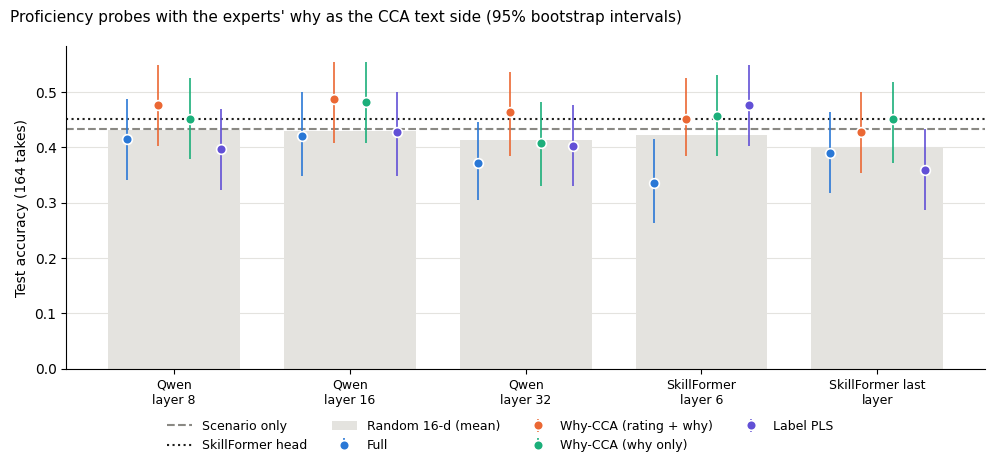

In [9]:
import matplotlib.pyplot as plt

COLORS = {"full": "#2a78d6", "why-CCA (rating + why)": "#eb6834", "why-CCA (why only)": "#1baf7a", "label PLS": "#6250d6"}
NULL_COLOR, GRID_COLOR, BAND_COLOR = "#8a8984", "#e4e3df", "#e4e3df"
reps = list(VIDEO)
x = np.arange(len(reps))
offsets = dict(zip(COLORS, np.linspace(-0.27, 0.27, len(COLORS))))
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(x, [table["All", f"{rep}: random"][0] for rep in reps], width=0.75, color=BAND_COLOR, label="Random 16-d (mean)")
ax.axhline(table["All", "scenario only"][0], color=NULL_COLOR, lw=1.5, ls="--", label="Scenario only")
ax.axhline(table["All", "SkillFormer (its own head)"][0], color="#1f1f1d", lw=1.5, ls=":", label="SkillFormer head")
for method, color in COLORS.items():
    values = np.array([table["All", f"{rep}: {method}"][0] for rep in reps])
    bounds = np.array([table["All", f"{rep}: {method}"][1] for rep in reps])
    ax.errorbar(x + offsets[method], values, yerr=[values - bounds[:, 0], bounds[:, 1] - values], ls="none", marker="o", ms=7,
                color=color, markeredgecolor="white", markeredgewidth=1.2, elinewidth=1.2, capsize=0, label=method.replace("why-CCA", "Why-CCA").replace("full", "Full").replace("label", "Label"))
ax.set_xticks(x, [rep.replace(" layer", "\nlayer") for rep in reps], fontsize=9)
ax.set_ylabel("Test accuracy (164 takes)")
ax.grid(axis="y", color=GRID_COLOR, lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=9, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.1))
fig.suptitle("Proficiency probes with the experts' why as the CCA text side (95% bootstrap intervals)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig("figures/why_cca_probe_accuracy.png", dpi=200, bbox_inches="tight")
plt.show()